In [1]:
import pandas as pd
column_names = [
    "radio", "mcc", "net", "area", "cell",
    "unit", "lon", "lat", "range", "samples",
    "changeable", "created", "updated", "average_signal"
]

df = pd.read_csv(
    r"C:\Users\HP\OneDrive\Documents\Final Year Project\data\raw\opencellid\621.csv",
    names = column_names,
    header = None
)
#THe file has no column names, but we can define

print(df.shape)

(99279, 14)


In [2]:
print(df.head())

  radio  mcc  net   area   cell  unit     lon     lat  range  samples  \
0   GSM  621   60  23061   7301     0  7.6197  9.0117   5658        5   
1   GSM  621   60  24821   2917     0  3.2988  6.6567   2960       20   
2   GSM  621   60  24822  30431     0  3.2450  6.7018   2935       22   
3   GSM  621   30  13025  24441     0  6.3366  4.9402   2026       23   
4   GSM  621   30  13025  24663     0  6.3507  4.9481   1134       10   

   changeable     created     updated  average_signal  
0           1  1459814336  1744954340               0  
1           1  1459732236  1733381585               0  
2           1  1459753520  1732084708               0  
3           1  1459707959  1777005228               0  
4           1  1459707959  1778298854               0  


In [3]:
print(df.info())

#.info gives us data type info

<class 'pandas.DataFrame'>
RangeIndex: 99279 entries, 0 to 99278
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   radio           99279 non-null  str    
 1   mcc             99279 non-null  int64  
 2   net             99279 non-null  int64  
 3   area            99279 non-null  int64  
 4   cell            99279 non-null  int64  
 5   unit            99279 non-null  int64  
 6   lon             99279 non-null  float64
 7   lat             99279 non-null  float64
 8   range           99279 non-null  int64  
 9   samples         99279 non-null  int64  
 10  changeable      99279 non-null  int64  
 11  created         99279 non-null  int64  
 12  updated         99279 non-null  int64  
 13  average_signal  99279 non-null  int64  
dtypes: float64(2), int64(11), str(1)
memory usage: 10.9 MB
None


In [4]:
print(df.describe())

#This gives numerical statistics

           mcc           net          area          cell          unit  \
count  99279.0  99279.000000  99279.000000  9.927900e+04  99279.000000   
mean     621.0     32.137270  22973.599885  1.167936e+06     -0.128063   
std        0.0      9.860915  16796.364288  1.101530e+07     16.098331   
min      621.0      0.000000      0.000000  0.000000e+00     -1.000000   
25%      621.0     30.000000  12126.000000  1.061200e+04     -1.000000   
50%      621.0     30.000000  21040.000000  2.628200e+04     -1.000000   
75%      621.0     30.000000  30704.000000  4.454600e+04     -1.000000   
max      621.0     60.000000  64425.000000  2.382022e+08    509.000000   

                lon           lat         range       samples  changeable  \
count  99279.000000  99279.000000  99279.000000  99279.000000     99279.0   
mean       6.284918      7.724374   2992.373745     11.627524         1.0   
std        2.154550      2.077817   3217.517009      9.393744         0.0   
min        2.878000      

In [5]:
print(df.columns)

Index(['radio', 'mcc', 'net', 'area', 'cell', 'unit', 'lon', 'lat', 'range',
       'samples', 'changeable', 'created', 'updated', 'average_signal'],
      dtype='str')


In [6]:
print(df.isnull().sum())
#To check the null values for each column

radio             0
mcc               0
net               0
area              0
cell              0
unit              0
lon               0
lat               0
range             0
samples           0
changeable        0
created           0
updated           0
average_signal    0
dtype: int64


In [7]:
#TO check duplicate values
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
#To inspect a column, alone, we can use .value_counts()

print(df["radio"].value_counts())

radio
GSM     97073
LTE      1659
UMTS      547
Name: count, dtype: int64


In [11]:
df["updated_date"].describe()

count                  99279
mean     2025-11-23 09:45:13
min      2024-11-19 00:54:21
25%      2025-07-11 05:35:14
50%      2026-01-19 05:27:02
75%      2026-04-24 04:32:22
max      2026-05-18 12:39:02
Name: updated_date, dtype: object

In [13]:
#How many unique values does every column have?
print(df.nunique().sort_values())

mcc                   1
changeable            1
average_signal        1
radio                 3
net                   6
samples              51
unit                202
area               1037
range             11543
cell              39695
lon               40837
updated_date      41900
updated           41900
lat               42399
created           56455
created_date      56455
dtype: int64


In [14]:
#What radio technologies are present?
print(df["radio"].value_counts())

radio
GSM     97073
LTE      1659
UMTS      547
Name: count, dtype: int64


In [15]:
#What network codes are present?
print(df["net"].value_counts())

net
30    67186
20    15621
50    12559
60     3910
3         2
0         1
Name: count, dtype: int64


In [16]:
#Investigate unit
print(df["unit"].value_counts().head(20))

unit
-1      90786
 0       8159
 78         6
 16         5
 445        4
 508        4
 497        4
 253        3
 44         3
 169        3
 15         3
 446        3
 444        3
 183        3
 374        3
 354        3
 351        3
 40         3
 482        3
 235        3
Name: count, dtype: int64


In [17]:
#Investigate repeated logical cells
cell_duplicates = df.duplicated(
    subset=["radio", "mcc", "net", "area", "cell"]
).sum()

print("Repeated logical-cell records:", cell_duplicates)

Repeated logical-cell records: 0


In [18]:
#Look at the range distribution
print(df["range"].describe())

print(
    df["range"].quantile(
        [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

count    99279.000000
mean      2992.373745
std       3217.517009
min        500.000000
25%       1000.000000
50%       1728.000000
75%       3757.000000
max      38410.000000
Name: range, dtype: float64
0.01     1000.00
0.05     1000.00
0.10     1000.00
0.25     1000.00
0.50     1728.00
0.75     3757.00
0.90     6558.00
0.95     8668.00
0.99    17398.22
Name: range, dtype: float64


<h2>Findings

The dataset is heavily dominated by GSM

You have:

GSM   97,073
LTE    1,659
UMTS     547

So about 97.8% of the records are GSM.


net has six values, but two are almost negligible

NO repeated logical cells

<h3>range is probably the most interesting variable so far


This is the part I really want you to notice.

Minimum      = 500 m
25th %       = 1000 m
Median       = 1728 m
Mean         = 2992 m
75th %       = 3757 m
90th %       = 6558 m
95th %       = 8668 m
99th %       = 17398 m
Maximum      = 38410 m

Look at:

Mean   = 2992 m
Median = 1728 m

The mean is almost twice the median.

That strongly suggests a right-skewed distribution.

In simple terms:

Most cells have relatively modest ranges, but a smaller number of cells have very large estimated ranges and pull the average upward.

<h1>Let's visualize the data

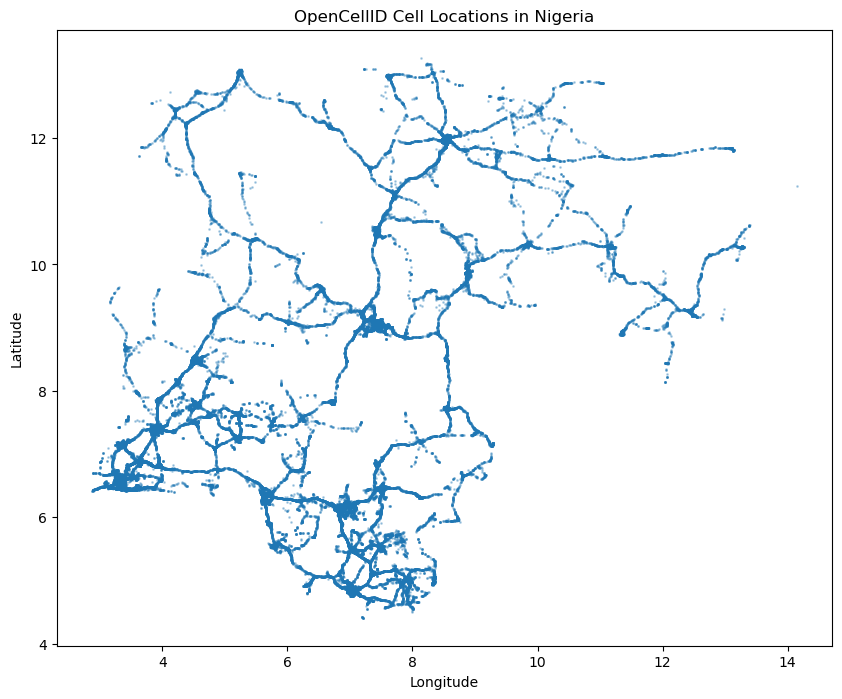

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.scatter(
    df["lon"],
    df["lat"],
    s=1,
    alpha=0.3
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("OpenCellID Cell Locations in Nigeria")

plt.show()

We cannot automatically interpret the empty areas as network coverage gaps.

OpenCellID is based on collected/crowdsourced measurements, so an area having few or no records can mean:

“few observations were collected here”

rather than:

“there is no network coverage here.”

<h2>Let's visualize the range

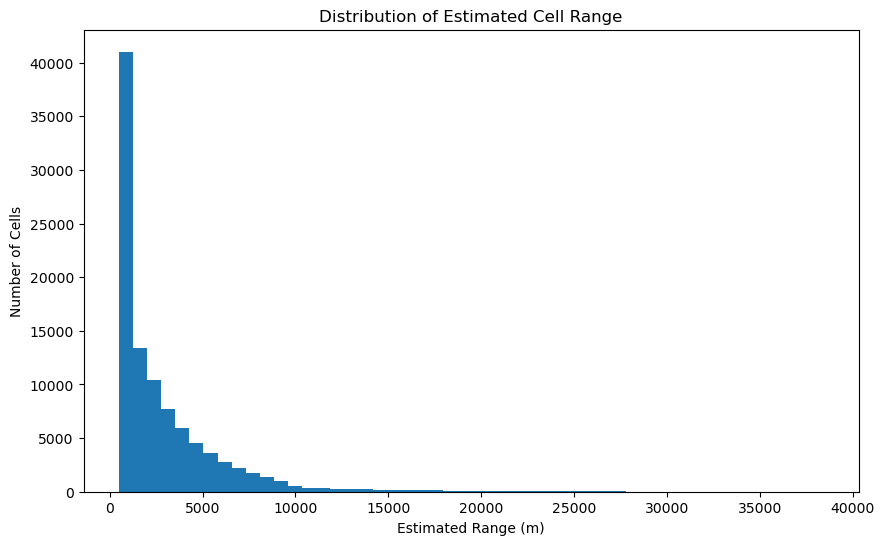

In [21]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["range"],
    bins=50
)

plt.xlabel("Estimated Range (m)")
plt.ylabel("Number of Cells")
plt.title("Distribution of Estimated Cell Range")

plt.show()

Remember that:

99,279 logical cells doesn't mean 99,279 physical sites.

Let's test how many unique coordinate locations we have.

In [22]:
print("Unique longitude values:", df["lon"].nunique())
print("Unique latitude values:", df["lat"].nunique())

Unique longitude values: 40837
Unique latitude values: 42399


In [23]:
print(
    "Rows sharing the exact same coordinates:",
    df.duplicated(subset=["lon", "lat"]).sum()
)

Rows sharing the exact same coordinates: 6158


In [24]:
coordinate_counts = (
    df.groupby(["lon", "lat"])
      .size()
      .sort_values(ascending=False)
)

print(coordinate_counts.head(20))

lon     lat   
8.8329  9.8680    11
3.3254  6.4870     9
3.5862  6.6062     8
3.3203  6.4412     8
6.3516  4.8285     8
5.9647  5.6349     8
3.2428  6.4684     8
3.3253  6.4870     8
6.3500  4.8451     8
7.2051  6.0663     8
7.2300  5.9743     8
7.6254  9.0062     8
7.6255  9.0062     8
5.2102  7.2506     7
4.8377  7.0462     7
6.8130  5.1024     7
3.0215  6.8964     7
3.3280  6.6141     7
6.3404  6.7166     7
3.4044  6.5231     7
dtype: int64


<h1>How many approximate physical sites are represented by these 99,279 cell records?

In [25]:
coordinate_counts = (
    df.groupby(["lon", "lat"])
      .size()
      .sort_values(ascending=False)
)

print("Number of unique coordinate pairs:", len(coordinate_counts))
print("\nTop 20 coordinate groups:")
print(coordinate_counts.head(20))

Number of unique coordinate pairs: 93121

Top 20 coordinate groups:
lon     lat   
8.8329  9.8680    11
3.3254  6.4870     9
3.5862  6.6062     8
3.3203  6.4412     8
6.3516  4.8285     8
5.9647  5.6349     8
3.2428  6.4684     8
3.3253  6.4870     8
6.3500  4.8451     8
7.2051  6.0663     8
7.2300  5.9743     8
7.6254  9.0062     8
7.6255  9.0062     8
5.2102  7.2506     7
4.8377  7.0462     7
6.8130  5.1024     7
3.0215  6.8964     7
3.3280  6.6141     7
6.3404  6.7166     7
3.4044  6.5231     7
dtype: int64


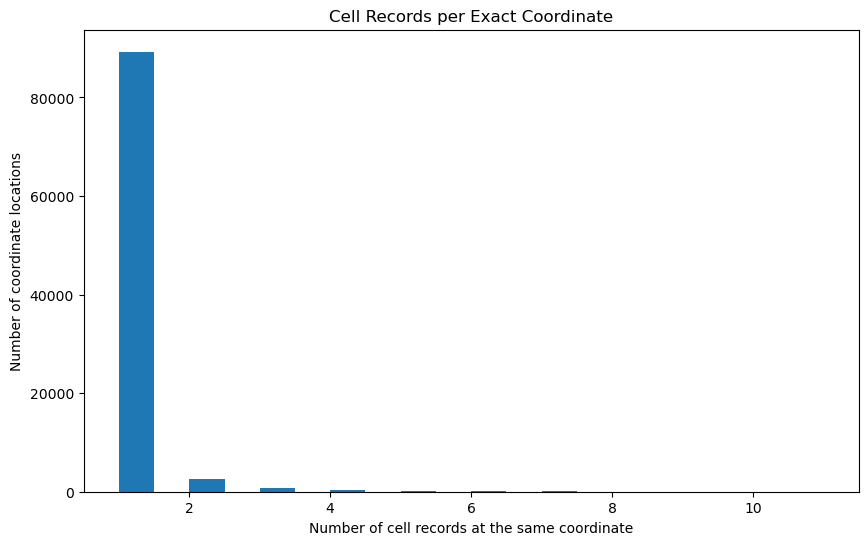

In [26]:
plt.figure(figsize=(10, 6))

plt.hist(coordinate_counts.values, bins=20)

plt.xlabel("Number of cell records at the same coordinate")
plt.ylabel("Number of coordinate locations")
plt.title("Cell Records per Exact Coordinate")

plt.show()

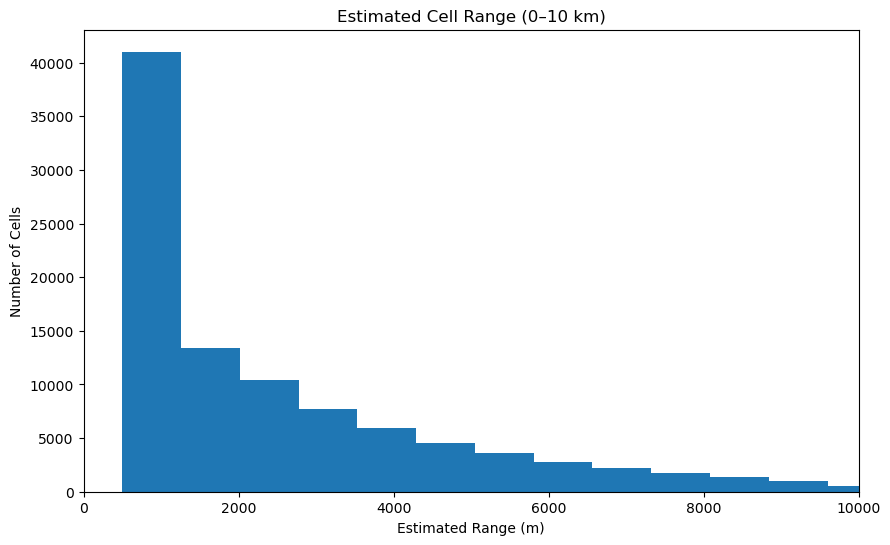

In [27]:
plt.figure(figsize=(10, 6))

plt.hist(df["range"], bins=50)

plt.xlim(0, 10000)

plt.xlabel("Estimated Range (m)")
plt.ylabel("Number of Cells")
plt.title("Estimated Cell Range (0–10 km)")

plt.show()